In [1]:
import numpy as np
import matplotlib.pyplot as plt
print("ready")

ready


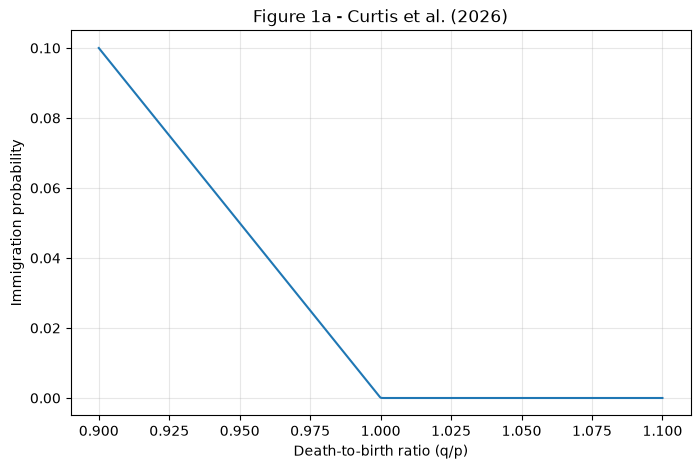

In [2]:
i = 1
N = 10000
def immigration_probability(alpha, i, N):
    if np.isclose(alpha, 1.0, rtol=0, atol=1e-12):
        return i / N
    x = np.log(alpha)
    if alpha > 1:
        return np.exp((i-N)*x) * (
            np.expm1(-i*x) / np.expm1(-N*x)
        )

    return np.expm1(i*x) / np.expm1(N*x)
ratios = np.linspace(0.9, 1.1, 500)
probabilities = [
    immigration_probability(a, i, N)
    for a in ratios
]
plt.figure(figsize=(8, 5))
plt.plot(ratios, probabilities)
plt.xlabel("Death-to-birth ratio (q/p)")
plt.ylabel("Immigration probability")
plt.title("Figure 1a - Curtis et al. (2026)")
plt.grid(alpha=0.3)
plt.show()

In [4]:
ratios = [0.90, 0.95, 0.99]
for alpha in ratios:
    result = immigration_probability(alpha, i, N)
    print("q/p =", alpha, "Probability =", round(result, 4))

q/p = 0.9 Probability = 0.1
q/p = 0.95 Probability = 0.05
q/p = 0.99 Probability = 0.01


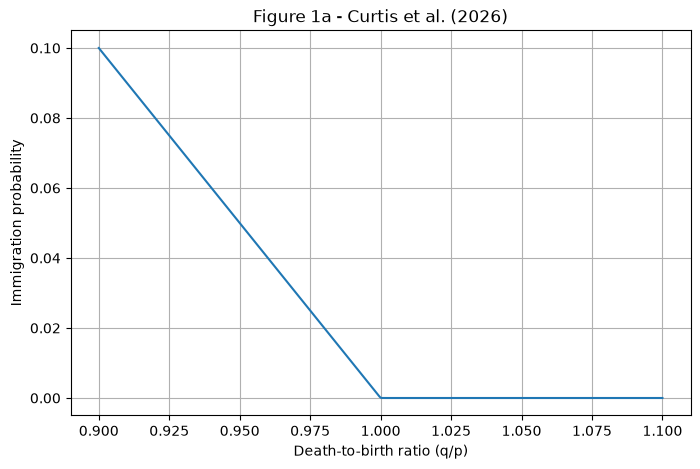

In [6]:
# Parameters from Figure 1a
i = 1
N = 10000
# Improved version of the probability equation
def immigration_probability_stable(alpha, i, N):
    if alpha == 1:
        return i / N
    x = np.log(alpha)
    if alpha > 1:
        return np.exp((i-N)*x) * (
            np.expm1(-i*x) / np.expm1(-N*x)
        )
    return np.expm1(i*x) / np.expm1(N*x)
# Include ratios below and above 1
ratios = np.linspace(0.9, 1.1, 501)
probabilities = []
for alpha in ratios:
    result = immigration_probability_stable(alpha, i, N)
    probabilities.append(result)
# Plot the results
plt.figure(figsize=(8, 5))
plt.plot(ratios, probabilities)
plt.xlabel("Death-to-birth ratio (q/p)")
plt.ylabel("Immigration probability")
plt.title("Figure 1a - Curtis et al. (2026)")
plt.grid(True)
plt.savefig("Figure_1a.png", dpi=300)
plt.show()

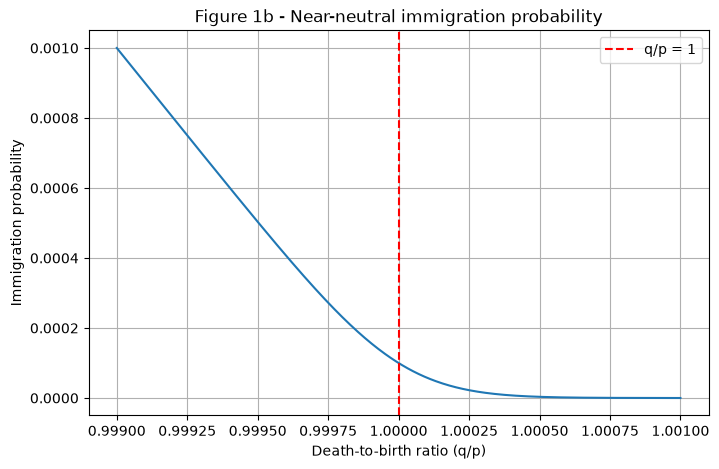

In [7]:
# Figure 1b: Zoom in around q/p = 1
i = 1
N = 10000
# Select ratios very close to 1
ratios_zoom = np.linspace(0.999, 1.001, 501)
# Reuse the probability function from Figure 1a
probabilities_zoom = []
for alpha in ratios_zoom:
    result = immigration_probability_stable(alpha, i, N)
    probabilities_zoom.append(result)
# Plot the zoomed graph
plt.figure(figsize=(8, 5))
plt.plot(ratios_zoom, probabilities_zoom)
# Mark the neutral case
plt.axvline(x=1, color="red", linestyle="--",
            label="q/p = 1")
plt.xlabel("Death-to-birth ratio (q/p)")
plt.ylabel("Immigration probability")
plt.title("Figure 1b - Near-neutral immigration probability")
plt.legend()
plt.grid(True)
plt.savefig("Figure_1b.png", dpi=300)
plt.show()

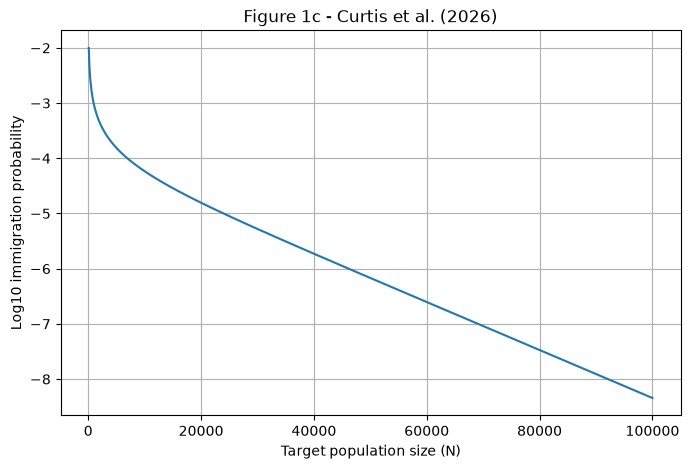

In [8]:
# Figure 1c: Immigration probability vs population size
i = 1
alpha = 1.0001

# Different target population sizes
population_sizes = np.arange(100, 100001, 100)

# Calculate log10 probability directly
# to avoid numerical underflow for large N
x = np.log(alpha)
log_probabilities = []
for N in population_sizes:
    log_p = (
        (i - N) * x
        + np.log(-np.expm1(-i * x))
        - np.log(-np.expm1(-N * x))
    )
    log_probabilities.append(log_p / np.log(10))

# Plot Figure 1c
plt.figure(figsize=(8, 5))
plt.plot(population_sizes, log_probabilities)
plt.xlabel("Target population size (N)")
plt.ylabel("Log10 immigration probability")
plt.title("Figure 1c - Curtis et al. (2026)")
plt.grid(True)
plt.savefig("Figure_1c.png", dpi=300)
plt.show()

In [9]:
# Original parameters from the authors' MATLAB file
q = 0.5002
p = 1 - q
c = 1 / 24
r = q / p
N = 1000

# Python translation of the authors' time_to_i() function
def time_to_i(p, q, c, r, N):

    Delta = np.zeros(N)
    M = np.zeros(N)

    # Initial value
    Delta[0] = 0

    # Authors' recurrence equation
    for i in range(1, N):
        Delta[i] = r * Delta[i-1] + c / (p * i)

    # Cumulative time
    M = np.cumsum(Delta)

    return M

# Run the function
M = time_to_i(p, q, c, r, N)

print("Time to reach population 1000:", M[-1])

Time to reach population 1000: 801.5397432071151


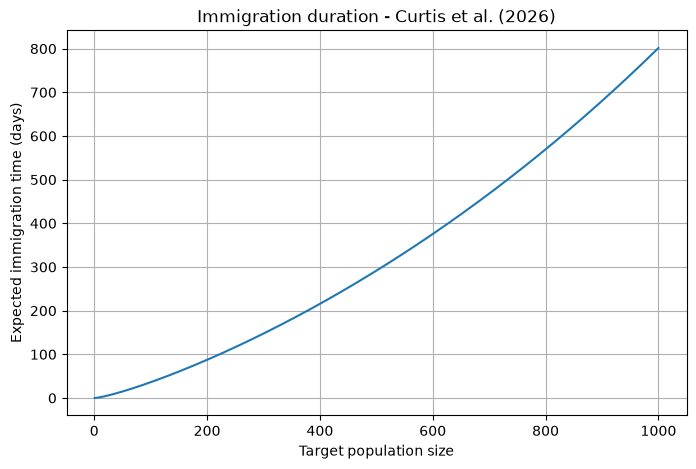

In [10]:

plt.figure(figsize=(8, 5))

plt.plot(range(1, N + 1), M)

plt.xlabel("Target population size")
plt.ylabel("Expected immigration time (days)")
plt.title("Immigration duration - Curtis et al. (2026)")
plt.grid(True)

plt.savefig("Immigration_Duration.png", dpi=300)
plt.show()

In [11]:
# Check immigration times at different population sizes
print("Population 10:", M[9])
print("Population 100:", M[99])
print("Population 500:", M[499])
print("Population 1000:", M[999])

# Check that immigration time increases
print("Times increase:", np.all(np.diff(M) >= 0))

Population 10: 1.6124141561140424
Population 100: 36.156072529260406
Population 500: 291.5620786256923
Population 1000: 801.5397432071151
Times increase: True


In [12]:
from scipy.integrate import quad

# Translation of the authors' time_to_i_an()
def time_to_i_an(p, q, c, r, N):
    M_an = np.zeros(N)
    for k in range(2, N + 1):

        # First term: numerical integration
        term1, error = quad(
            lambda t: (1 - t**(k-1)) / (1 - t),
            0,
            1/r
        )

        # Second term: approximation used in MATLAB
        term2 = (
            np.log(k-1)
            + 0.57721
            + 1/(2*(k-1))
            - 1/(12*(k-1)**3)
        )
        M_an[k-1] = (
            c / (p*(r-1))
            * (r**k * term1 - term2)
        )
    return M_an

# Calculate the analytical results
M_an = time_to_i_an(p, q, c, r, N)
print("Recurrence result:", M[-1])
print("Analytical result:", M_an[-1])
print("Difference:", abs(M[-1] - M_an[-1]))

Recurrence result: 801.5397432071151
Analytical result: 801.540324611777
Difference: 0.0005814046619434521


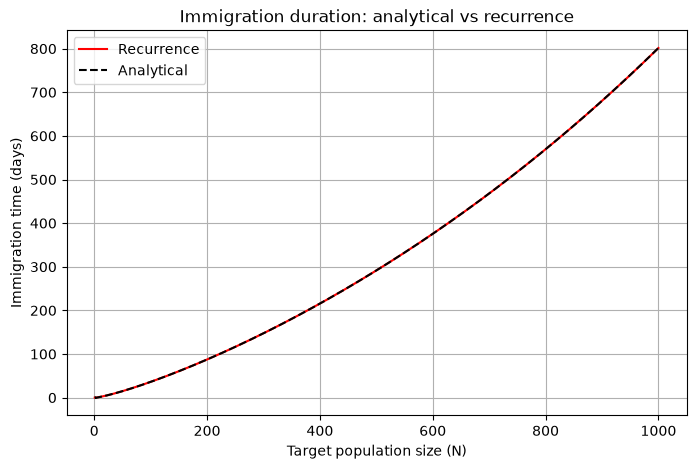

In [13]:
# Compare the two immigration-duration methods
plt.figure(figsize=(8, 5))
plt.plot(
    range(1, N + 1),
    M,
    label="Recurrence",
    color="red"
)
plt.plot(
    range(1, N + 1),
    M_an,
    label="Analytical",
    color="black",
    linestyle="--"
)
plt.xlabel("Target population size (N)")
plt.ylabel("Immigration time (days)")
plt.title("Immigration duration: analytical vs recurrence")
plt.legend()
plt.grid(True)
plt.savefig("Immigration_Comparison.png", dpi=300)
plt.show()

In [14]:
# Parameters from the authors' MATLAB code
q = 0.5002
p = 1 - q
c = 1 / 24
r = q / p
N = 1000

# Python translation of the authors' extinction() function
def extinction(p, q, c, r, N):
    Delta = np.zeros(N)
    # Initial value from the MATLAB code
    Delta[0] = -(c / p) * np.log(1 - 1/r)
    # Recurrence equation
    for i in range(1, N):
        Delta[i] = r * Delta[i-1] - c / (p*i)
    # Cumulative extinction times
    T = np.cumsum(Delta)
    return T
# Run the extinction calculation
T = extinction(p, q, c, r, N)
print("Time to extinction from population 1000:", T[-1])

Time to extinction from population 1000: 108.84558689534451


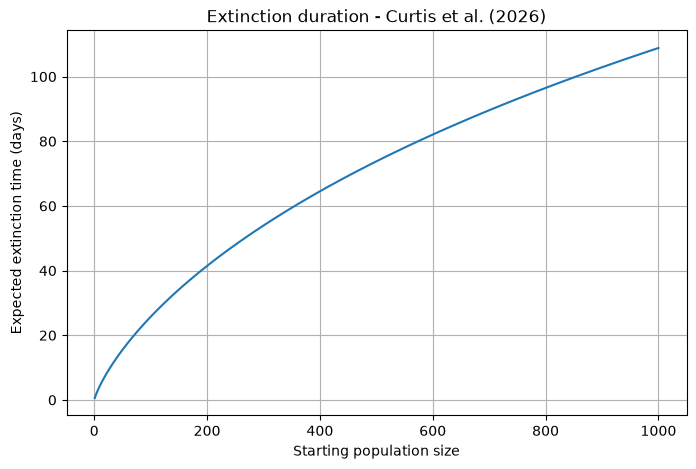

In [15]:
plt.figure(figsize=(8, 5))
plt.plot(range(1, N + 1), T)
plt.xlabel("Starting population size")
plt.ylabel("Expected extinction time (days)")
plt.title("Extinction duration - Curtis et al. (2026)")
plt.grid(True)
plt.savefig("Extinction_Duration.png", dpi=300)
plt.show()

In [16]:
# Python translation of the authors' extinction_an()
def extinction_an(p, q, c, r, N):
    T_an = np.zeros(N)
    for k in range(2, N + 1):
        # Numerical integral from the MATLAB code
        term1, error = quad(
            lambda t: (1 - t**(k-1)) / (1 - t),
            0,
            1/r
        )
        # Authors' harmonic-number approximation
        term2 = (
            np.log(k-1)
            + 0.57721
            + 1/(2*(k-1))
            - 1/(12*(k-1)**3)
        )
        term3 = (r**k - 1) * np.log(r/(r-1))

        T_an[k-1] = (
            -c / (p*(r-1))
            * (r**k * term1 - term2 - term3)
        )
    return T_an

# Run the analytical calculation
T_an = extinction_an(p, q, c, r, N)
print("Recurrence extinction:", T[-1])
print("Analytical extinction:", T_an[-1])
print("Difference:", abs(T[-1] - T_an[-1]))

Recurrence extinction: 108.84558689534451
Analytical extinction: 108.8450054906899
Difference: 0.000581404654610651


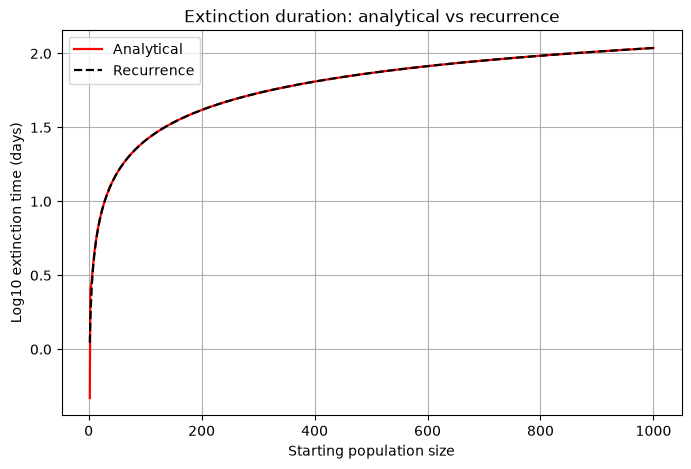

In [17]:
# Plot both extinction calculations
plt.figure(figsize=(8, 5))

# Start at population 2 because the analytical
# array contains zero at population 1
population = np.arange(2, N + 1)
plt.plot(
    population,
    np.log10(T_an[1:]),
    color="red",
    label="Analytical",
    linewidth=1.6
)
plt.plot(
    population,
    np.log10(T[1:]),
    color="black",
    linestyle="--",
    label="Recurrence",
    linewidth=1.6
)
plt.xlabel("Starting population size")
plt.ylabel("Log10 extinction time (days)")
plt.title("Extinction duration: analytical vs recurrence")
plt.legend()
plt.grid(True)
plt.savefig("Extinction_Comparison.png", dpi=300)
plt.show()

In [18]:
import pandas as pd
results = pd.DataFrame({
    "Calculation": ["Immigration", "Extinction"],
    "Recurrence_days": [M[-1], T[-1]],
    "Analytical_days": [M_an[-1], T_an[-1]]
})
results["Absolute_difference"] = abs(
    results["Recurrence_days"] -
    results["Analytical_days"]
)
print(results)
results.to_csv("Day1_Results.csv", index=False)

   Calculation  Recurrence_days  Analytical_days  Absolute_difference
0  Immigration       801.539743       801.540325             0.000581
1   Extinction       108.845587       108.845005             0.000581


In [19]:
# Compare our calculations with Table 1
import pandas as pd
N = 1000
c = 1 / 24  #authors' MATLAB example
ratios = [1.01, 1.001, 1.0001]
published_immigration = [1960000, 2130, 1300]
published_extinction = [59, 234, 1010]
rows = []
for j, r in enumerate(ratios):
    # Calculate p and q so that p + q = 1
    p = 1 / (1 + r)
    q = r / (1 + r)

    # Reuse the authors' translated functions
    M_result = time_to_i(p, q, c, r, N)[-1]
    T_result = extinction(p, q, c, r, N)[-1]
    rows.append({
        "q/p": r,
        "Python immigration": M_result,
        "Table 1 immigration": published_immigration[j],
        "Python extinction": T_result,
        "Table 1 extinction": published_extinction[j]
    })

comparison = pd.DataFrame(rows)
print(comparison.to_string(index=False))
comparison.to_csv("Table1_Comparison.csv", index=False)

   q/p  Python immigration  Table 1 immigration  Python extinction  Table 1 extinction
1.0100       810042.162541              1960000          24.805373                  59
1.0010          891.198797                 2130          97.779313                 234
1.0001          566.200410                 1300         241.022930                1010


In [20]:
# Step 18: Compare published results with Python
comparison["Immigration ratio"] = (
    comparison["Table 1 immigration"] /
    comparison["Python immigration"]
)
comparison["Extinction ratio"] = (
    comparison["Table 1 extinction"] /
    comparison["Python extinction"]
)
print(comparison[
    ["q/p", "Immigration ratio", "Extinction ratio"]
].round(3).to_string(index=False))

  q/p  Immigration ratio  Extinction ratio
1.010              2.420             2.379
1.001              2.390             2.393
1.000              2.296             4.190


In [21]:
# Diagnostic: test a different time constant
c_test = 0.1
N = 1000
for r in [1.01, 1.001, 1.0001]:
    p = 1 / (1 + r)
    q = r / (1 + r)
    M_test = time_to_i(p, q, c_test, r, N)[-1]
    T_test = extinction(p, q, c_test, r, N)[-1]
    print("q/p =", r)
    print("Immigration:", round(M_test, 2), "days")
    print("Extinction:", round(T_test, 2), "days")
    print()

q/p = 1.01
Immigration: 1944101.19 days
Extinction: 59.53 days

q/p = 1.001
Immigration: 2138.88 days
Extinction: 234.67 days

q/p = 1.0001
Immigration: 1358.88 days
Extinction: 578.46 days



In [22]:
# Check the remaining Table 1 discrepancy
r = 1.0001
p = 1 / (1 + r)
q = r / (1 + r)
c = 0.1
N = 1000
# Recurrence calculation
T_check = extinction(p, q, c, r, N)

# Analytical calculation
T_an_check = extinction_an(p, q, c, r, N)
print("Recurrence extinction:", T_check[-1])
print("Analytical extinction:", T_an_check[-1])
print("Published Table 1:", 1010)
print("Difference between Python methods:",
      abs(T_check[-1] - T_an_check[-1]))

Recurrence extinction: 578.4550317540447
Analytical extinction: 578.4438682262639
Published Table 1: 1010
Difference between Python methods: 0.01116352778080909


In [23]:
#Extinction recurrence
r = 1.0001
p = 1 / (1 + r)
q = r / (1 + r)
c = 0.1
N = 1000
T_check = extinction(p, q, c, r, N)
print("Birth probability p:", p)
print("Death probability q:", q)
print("Death-to-birth ratio:", q / p)
print("Extinction from 1 bacterium:", T_check[0])
print("Extinction from 10 bacteria:", T_check[9])
print("Extinction from 100 bacteria:", T_check[99])
print("Extinction from 1000 bacteria:", T_check[999])

Birth probability p: 0.49997500124993755
Death probability q: 0.5000249987500626
Death-to-birth ratio: 1.0001
Extinction from 1 bacterium: 1.8421801777989397
Extinction from 10 bacteria: 14.57067799629751
Extinction from 100 bacteria: 101.01498946271451
Extinction from 1000 bacteria: 578.4550317540447


In [24]:
# Parameters from the authors' MATLAB example
q = 0.5002
p = 1 - q
c = 1 / 24
r = q / p
N = 1000

# Python translation of extinction_noise()
def extinction_noise(p, q, c, r, N, noise, seed=42):
    rng = np.random.default_rng(seed)
    Delta = np.zeros(N)
    T = np.zeros(N)
    
    # Authors' noise procedure
    np_new = p + (0.5 - rng.random()) * noise
    r_new = (1 - np_new) / np_new

    # Initial condition from MATLAB
    Delta[0] = -(c / p) * np.log(1 - 1/r_new)

    # Recurrence equation
    for i in range(1, N):
        Delta[i] = (
            r_new * Delta[i-1]
            - c / (np_new * i)
        )
    T = np.cumsum(Delta)
    return T

# Run one noisy calculation
T_noise = extinction_noise(
    p, q, c, r, N,
    noise=0.0004,
    seed=42
)
print("Noisy extinction time:", T_noise[-1])

Noisy extinction time: 87.5637566510841


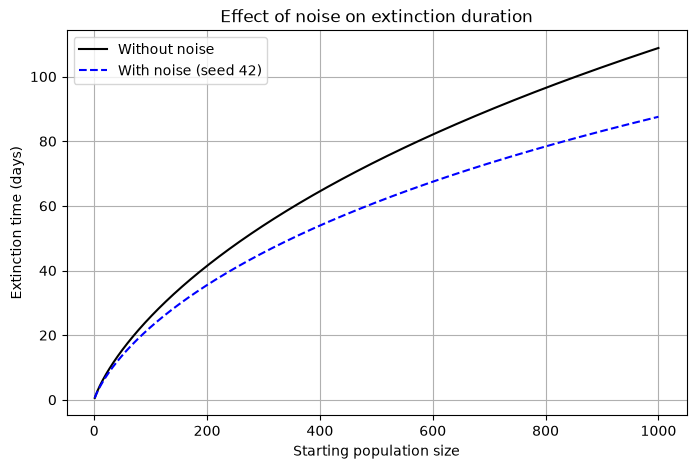

In [25]:
# Original extinction calculation without noise
T_original = extinction(p, q, c, r, N)

# Compare original and noisy calculations
plt.figure(figsize=(8, 5))
plt.plot(
    range(1, N + 1),
    T_original,
    label="Without noise",
    color="black"
)
plt.plot(
    range(1, N + 1),
    T_noise,
    label="With noise (seed 42)",
    color="blue",
    linestyle="--"
)
plt.xlabel("Starting population size")
plt.ylabel("Extinction time (days)")
plt.title("Effect of noise on extinction duration")
plt.legend()
plt.grid(True)
plt.savefig("Figure_A3_initial.png", dpi=300)
plt.show()

In [27]:
# Store extinction times from 10 noisy simulations
extinction_times = []
for seed in range(10):
    T_sim = extinction_noise(
        p, q, c, r, N,
        noise=0.0004,
        seed=seed
    )
    extinction_times.append(T_sim[-1])

# Convert to NumPy array
extinction_times = np.array(extinction_times)

print("Without noise:", round(T_original[-1], 2), "days")
print("Minimum with noise:", round(np.min(extinction_times), 2), "days")
print("Maximum with noise:", round(np.max(extinction_times), 2), "days")
print("Mean with noise:", round(np.mean(extinction_times), 2), "days")
print("Standard deviation:", round(np.std(extinction_times), 2), "days")

Without noise: 108.85 days
Minimum with noise: 78.76 days
Maximum with noise: 218.57 days
Mean with noise: 114.95 days
Standard deviation: 39.93 days


In [28]:
noise_results = pd.DataFrame({
    "Seed": range(10),
    "Extinction_time_days": extinction_times
})
noise_results.to_csv(
    "Figure_A3_noise_results.csv",
    index=False
)
print(noise_results)
print("CSV file saved successfully.")

   Seed  Extinction_time_days
0     0             96.736626
1     1            107.642350
2     2            145.041678
3     3            218.573857
4     4             78.758036
5     5             85.772147
6     6            105.083003
7     7             97.648879
8     8            131.975466
9     9             82.280091
CSV file saved successfully.


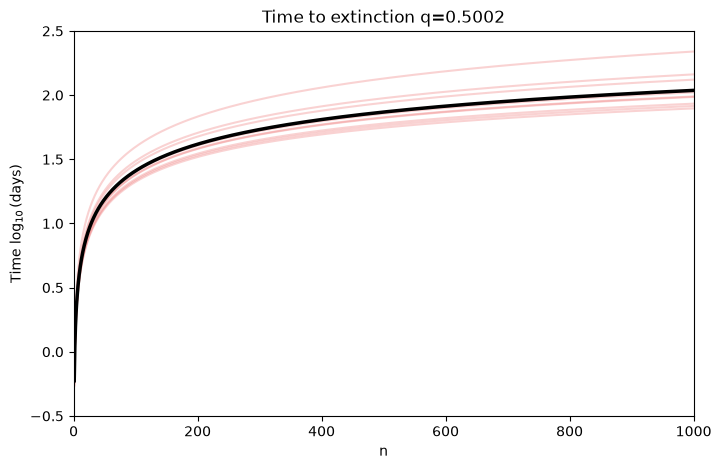

In [29]:
plt.figure(figsize=(8, 5))

# Plot 10 noisy extinction curves
for seed in range(10):
    T_sim = extinction_noise(
        p, q, c, r, N,
        noise=0.0004,
        seed=seed
    )
    plt.plot(
        range(1, N + 1),
        np.log10(T_sim),
        color="lightcoral",
        alpha=0.35,
        linewidth=1.5
    )

# Plot original extinction curve
plt.plot(
    range(1, N + 1),
    np.log10(T_original),
    color="black",
    linewidth=2.5
)
plt.xlabel("n")
plt.ylabel(r"Time $\log_{10}$(days)")
plt.title("Time to extinction q=0.5002")
plt.xlim(0, 1000)
plt.ylim(-0.5, 2.5)
plt.savefig(
    "Figure_A3_reproduction.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [30]:

# Exercise 4: Equal birth and death probabilities

p = 0.5
q = 0.5
N = 1000

# Neutral immigration probability
def neutral_probability(i, N):
    return i / N

for i in [1, 2, 10]:
    P = neutral_probability(i, N)

    print("Starting population:", i)
    print("Target population:", N)
    print("Probability:", P)
    print()

Starting population: 1
Target population: 1000
Probability: 0.001

Starting population: 2
Target population: 1000
Probability: 0.002

Starting population: 10
Target population: 1000
Probability: 0.01



In [31]:
from scipy.special import digamma
# Harmonic number H_n
def harmonic(n):
    return digamma(n + 1) + np.euler_gamma

# Neutral extinction with carrying capacity
def neutral_extinction(i, K, c):
    return 2 * c * (
        i * (harmonic(K - 1) - harmonic(i - 1))
        + (i - 1)
    )
    
# Test parameters
K = 1000
c = 1 / 24
for i in [1, 2, 10, 100]:
    T = neutral_extinction(i, K, c)
    print("Starting population:", i)
    print("Extinction time:", round(T, 4), "days")
    print()

Starting population: 1
Extinction time: 0.6237 days

Starting population: 2
Extinction time: 1.1641 days

Starting population: 10
Extinction time: 4.6296 days

Starting population: 100
Extinction time: 27.4758 days



In [32]:
import numpy as np

# Parameters
K = 1000
c = 1 / 24

# Correct recurrence for the neutral extinction formula
Delta = np.zeros(K)

# Upper boundary condition
Delta[K - 1] = 0

# Calculate backwards
for i in range(K - 2, -1, -1):
    n = i + 1
    Delta[i] = Delta[i + 1] + 2 * c / n

# Calculate extinction time
T_recurrence = np.cumsum(Delta)

# Compare results
for i in [1, 2, 10, 100]:
    analytical = neutral_extinction(i, K, c)
    recurrence = T_recurrence[i - 1]

    print("Starting population:", i)
    print("Analytical:", round(analytical, 4))
    print("Recurrence:", round(recurrence, 4))
    print("Difference:", round(abs(analytical - recurrence), 8))
    print()

Starting population: 1
Analytical: 0.6237
Recurrence: 0.6237
Difference: 0.0

Starting population: 2
Analytical: 1.1641
Recurrence: 1.1641
Difference: 0.0

Starting population: 10
Analytical: 4.6296
Recurrence: 4.6296
Difference: 0.0

Starting population: 100
Analytical: 27.4758
Recurrence: 27.4758
Difference: 0.0



In [33]:
import sys
import numpy
import scipy
import matplotlib
import pandas

print("Python:", sys.version.split()[0])
print("NumPy:", numpy.__version__)
print("SciPy:", scipy.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Pandas:", pandas.__version__)

Python: 3.14.8
NumPy: 2.5.4
SciPy: 1.18.1
Matplotlib: 3.11.2
Pandas: 3.0.6
